# Contact-map cell embedding with FastHigashi

FastHigashi (Zhang et al. 2022, *Cell Systems*) embeds single-cell Hi-C maps by a tensor decomposition of
all cells' contact maps, chromosome by chromosome.  This tutorial runs it on sci-Hi-C of two human cell lines.
It covers the whole path:

- write the Higashi input files with `uchrom.io.contacts` (`make_higashi_config`, `write_label_info`);
- run FastHigashi through `uchrom.emb.higashi.run`, which stores the embedding in `cd.cellm["higashi"]`;
- score the embedding against the known cell types (ARI / NMI);
- compute t-SNE / UMAP and Leiden clusters with `uchrom.emb.embed_cells` / `cluster_cells`.

- **Data**: Kim et al. 2020 (*Nat. Commun.* 11:6386) sci-Hi-C of an H1 ES cell (H1Esc) and foreskin
  fibroblast (HFF) mix: 1,931 cells at 500 kb, hg19, with cell-type labels.  The files are
  `example-data/H1Esc-HFF.R1.tar.gz` and `.labeled` (128 MB, downloaded on first run; see the catalog).
- **Runtime**: 3–5 min on a laptop CPU (FastHigashi itself takes 2–4 min), for 150 cells of each type picked
  at random.
- **Requirements**: FastHigashi is an optional dependency and is not on PyPI.  Install it from GitHub in an
  environment with NumPy < 2, because FastHigashi 0.1.1a0 calls `np.array(..., copy=False)`:

  ```
  pip install "numpy<2" opt_einsum tqdm psutil
  pip install git+https://github.com/ma-compbio/Fast-Higashi
  ```

In [1]:
import importlib.util
import json
import shutil
import tarfile
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from chromdata import ChromData
from uchrom import emb
from uchrom.emb.higashi import run as higashi_run
from uchrom.io.contacts import make_higashi_config, write_label_info

plt.rcParams["figure.dpi"] = 90
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by umap-learn


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)
if importlib.util.find_spec("fasthigashi") is None:
    raise ImportError("FastHigashi is not installed: see the install commands in the first cell")
print("numpy", np.__version__)
T0 = time.time()

numpy 1.26.4


## 1. The data

Each cell's `.matrix` file is a sparse list `bin1, bin2, count, weight, chrom1, chrom2`.  `bin1` and `bin2`
are **genome-wide** 500 kb bin numbers: the bins of chr1, then chr2, and so on, in hg19 order.  The helper
downloads the tarball and the labels from the URLs in `example-data/README.md` if they are missing, and
extracts the tarball once.

In [2]:
KIM2020 = "https://noble.gs.washington.edu/proj/schic-topic-model/data/"


def find_kim2020():
    tar_path, labels = DATA / "H1Esc-HFF.R1.tar.gz", DATA / "H1Esc-HFF.R1.labeled"
    matrices = DATA / "H1Esc-HFF.R1"
    if not labels.exists():
        urllib.request.urlretrieve(KIM2020 + "matrix_labels/H1Esc-HFF.R1.labeled", labels)
    if not matrices.exists():
        if not tar_path.exists():
            print("downloading H1Esc-HFF.R1.tar.gz (128 MB) ...")
            urllib.request.urlretrieve(KIM2020 + "matrix_files/H1Esc-HFF.R1.tar.gz", tar_path)
        with tarfile.open(tar_path, "r:gz") as tf:
            tf.extractall(DATA, filter="data")
    return matrices, labels


matrices_dir, labels_path = find_kim2020()
labels = pd.read_csv(labels_path, sep="\t", header=None, names=["matrix", "cell_type"])
print(f"{len(labels):,} cells:", labels["cell_type"].value_counts().to_dict())
pd.read_csv(matrices_dir / labels["matrix"].iloc[0], sep="\t", header=None, nrows=3,
            names=["bin1", "bin2", "count", "weight", "chrom1", "chrom2"])

1,931 cells: {'HFF': 1181, 'H1Esc': 750}


,bin1,bin2,count,weight,chrom1,chrom2
0,1868,1868,1,0.250000,human_chr5,human_chr5
1,588,3317,1,0.288675,human_chr2,human_chr9
2,1774,4583,1,0.218218,human_chr5,human_chr14


## 2. Pick the cells and convert their contacts to Higashi input

We pick 150 H1Esc and 150 HFF cells at random (seed 0).  FastHigashi needs population diversity, and more cells
give a better embedding but take longer.

Each chromosome's first genome-wide bin follows from the hg19 chromosome sizes: it is the number of 500 kb bins
of all chromosomes before it.  Do not take the smallest bin seen in the data instead.  On the acrocentric
chromosomes (13, 14, 15, 21, 22) the unmappable short arm has no contacts, so that would shift every contact
by up to 19 Mb.  The check below makes sure that every observed bin falls inside its chromosome.

In [3]:
RESOLUTION = 500_000
HG19 = {"chr1": 249250621, "chr2": 243199373, "chr3": 198022430, "chr4": 191154276, "chr5": 180915260,
        "chr6": 171115067, "chr7": 159138663, "chr8": 146364022, "chr9": 141213431, "chr10": 135534747,
        "chr11": 135006516, "chr12": 133851895, "chr13": 115169878, "chr14": 107349540, "chr15": 102531392,
        "chr16": 90354753, "chr17": 81195210, "chr18": 78077248, "chr19": 59128983, "chr20": 63025520,
        "chr21": 48129895, "chr22": 51304566, "chrX": 155270560}           # chrY has no contacts here
n_bins = {c: -(-size // RESOLUTION) for c, size in HG19.items()}
offset = dict(zip(n_bins, np.r_[0, np.cumsum(list(n_bins.values()))[:-1]]))

N_PER_TYPE = 150
sub = pd.concat([labels[labels["cell_type"] == t].sample(N_PER_TYPE, random_state=0)
                 for t in ("H1Esc", "HFF")]).reset_index(drop=True)
sub["cell_name"] = sub["matrix"].str.removesuffix("_500000.matrix")


def matrix_to_higashi(path):
    m = pd.read_csv(path, sep="\t", header=None, names=["bin1", "bin2", "count", "weight", "chrom1", "chrom2"])
    c1, c2 = m["chrom1"].str.removeprefix("human_"), m["chrom2"].str.removeprefix("human_")
    b1, b2 = m["bin1"] - c1.map(offset), m["bin2"] - c2.map(offset)
    assert ((b1 >= 0) & (b1 < c1.map(n_bins)) & (b2 >= 0) & (b2 < c2.map(n_bins))).all(), path.name
    return pd.DataFrame({"chrom1": c1, "pos1": b1 * RESOLUTION, "chrom2": c2, "pos2": b2 * RESOLUTION,
                         "count": m["count"]})


work = OUT / "higashi_kim2020"
shutil.rmtree(work, ignore_errors=True)           # FastHigashi caches per input set: start clean
higashi_dir = work / "input"
(higashi_dir / "data").mkdir(parents=True, exist_ok=True)
files, n_contacts = [], []
for row in sub.itertuples():
    contacts = matrix_to_higashi(matrices_dir / row.matrix)
    path = higashi_dir / "data" / f"{row.cell_name}.txt"
    contacts.to_csv(path, sep="\t", index=False, header=False)      # chrom1 pos1 chrom2 pos2 count
    files.append(str(path.resolve()))
    n_contacts.append(int(contacts["count"].sum()))
sub["n_contacts"] = n_contacts
print(f"{len(sub)} cells; median contacts per cell:", sub.groupby("cell_type")["n_contacts"].median().to_dict())

300 cells; median contacts per cell: {'H1Esc': 7570.0, 'HFF': 2794.0}


The remaining input files are the following:

- `filelist.txt`: one contact file per cell.
- `label_info.pickle`: per-cell metadata, in the same order.  FastHigashi returns the embedding in this order.
- `chromsizes.tsv`
- `config.JSON`: genome, resolution, chromosomes and paths.

`write_higashi_inputs` writes all of them for `.pairs` files.  Here the contacts come from `.matrix` files,
so we call its helpers `write_label_info` and `make_higashi_config` directly.

In [4]:
(higashi_dir / "filelist.txt").write_text("\n".join(files) + "\n")
write_label_info(sub[["cell_name", "cell_type", "n_contacts"]], higashi_dir / "label_info.pickle")
pd.Series(HG19).to_csv(higashi_dir / "chromsizes.tsv", sep="\t", header=False)
config = make_higashi_config(data_dir=str(higashi_dir), genome_reference="hg19", resolution=RESOLUTION,
                             chrom_list=list(HG19),
                             overrides={"genome_reference_path": str(higashi_dir / "chromsizes.tsv")})
(higashi_dir / "config.JSON").write_text(json.dumps(config, indent=2))
print(sorted(p.name for p in higashi_dir.iterdir()))
{k: config[k] for k in ("resolution", "input_format", "contact_header", "header_included")}

['chromsizes.tsv', 'config.JSON', 'data', 'filelist.txt', 'label_info.pickle']


{'resolution': 500000,
 'input_format': 'higashi_v2',
 'contact_header': ['chrom1', 'pos1', 'chrom2', 'pos2', 'count'],
 'header_included': False}

## 3. A `ChromData` of the cells

These data have contacts but no 3-D coordinates, so the `ChromData` has cells and no spots.  This is the same
layout as the scHiCAR store in `cell_embeddings.ipynb`.  `higashi.run` matches the rows of the embedding to
`cd.cells` by the `cell_name` column.

In [5]:
no_spots = pd.DataFrame({c: pd.Series(dtype=t) for c, t in
                         [("chrom", str), ("start", np.int64), ("end", np.int64), ("trace_id", str), ("cell_id", str)]})
cd = ChromData(np.zeros((0, 3)), no_spots,
               cells=sub.set_index(pd.Index(sub["cell_name"], name="cell_id"))[["cell_name", "cell_type", "n_contacts"]],
               uns={"genome_assembly": "hg19", "source": "Kim et al. 2020 sci-Hi-C (H1Esc-HFF.R1), 500 kb"})
print(cd.n_cells, "cells;", list(cd.cells.columns))

300 cells; ['cell_name', 'cell_type', 'n_contacts']


## 4. Run FastHigashi

`higashi.run` drives FastHigashi's four steps (`fast_process_data`, `prep_dataset`, `run_model`,
`fetch_cell_embedding`).  It writes the chosen embedding variant to `cd.cellm["higashi"]`, with rows in the order
of `cd.cells`.  It also makes `pin_memory` a no-op on machines without CUDA, such as Apple Silicon.

We pass the following options:

- `do_conv`, `do_rwr`, `do_col`: smoothing, random walk with restart and column normalisation of the very
  sparse maps;
- rank 64;
- `embed_variant="embed_l2_norm_correct_coverage_fh"`: the embedding after FastHigashi regresses out each
  cell's coverage.  The HFF cells here have about 3× fewer contacts than the H1Esc cells, so coverage alone would
  separate the two types in the uncorrected embedding.

`wrapper_factory` lets us keep the FastHigashi object, so that we can compare the variants afterwards.
FastHigashi prints a lot of progress output, so we send it to a log file.  Its initialisation is random, so we
seed NumPy and PyTorch.

In [6]:
import contextlib
import os
import sys


@contextlib.contextmanager
def to_log(path):
    # route Python-level and subprocess output (fd 1 / 2) to a file
    sys.stdout.flush(); sys.stderr.flush()
    with open(path, "w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        saved = os.dup(1), os.dup(2)
        os.dup2(log.fileno(), 1); os.dup2(log.fileno(), 2)
        try:
            yield
        finally:
            log.flush()
            os.dup2(saved[0], 1); os.dup2(saved[1], 2)
            os.close(saved[0]); os.close(saved[1])


models = []


def keep_model(*args):
    from fasthigashi.FastHigashi_Wrapper import FastHigashi
    models.append(FastHigashi(*args))
    return models[-1]


import torch

torch.manual_seed(0); np.random.seed(0)          # FastHigashi's initialisation and final SVD are random
log_path = work / "fasthigashi.log"
t = time.time()
with to_log(log_path):
    cd = higashi_run(cd, contacts_dir=higashi_dir, rank=64, cache_dir=work / "cache", result_dir=work / "result",
                     wrapper_kwargs={"do_conv": True, "do_rwr": True, "do_col": True},
                     embed_variant="embed_l2_norm_correct_coverage_fh", wrapper_factory=keep_model)
print(f"FastHigashi: {time.time() - t:.0f} s; cd.cellm['higashi'] {cd.cellm['higashi'].shape}; "
      f"log in {log_path.relative_to(REPO)}")
print(*[line for line in log_path.read_text().splitlines() if "pass qc" in line or line.startswith("PARAFAC2")][-3:],
      sep="\n")
{k: v for k, v in cd.uns["higashi"].items() if k not in ("config_path", "result_dir")}

FastHigashi: 126 s; cd.cellm['higashi'] (300, 64); log in tutorials/_out/higashi_kim2020/fasthigashi.log
PARAFAC2 re=0.613 1.10e-02 variation min4.3e-03 at chrom 22, max1.9e-02 at chrom 17 takes 8.2s
PARAFAC2 re=0.611 5.91e-03 variation min1.7e-03 at chrom 22, max1.1e-02 at chrom 17 takes 8.2s
PARAFAC2 re=0.610 3.69e-03 variation min8.8e-04 at chrom 22, max6.8e-03 at chrom 17 takes 8.1s


{'method': 'fast',
 'rank': 64,
 'embed_variant': 'embed_l2_norm_correct_coverage_fh'}

## 5. Score the embedding against the cell types

We cluster the embedding into k = 2 groups with k-means and compare the groups with the labels by ARI and NMI
(0 = chance, 1 = perfect).

FastHigashi also flags cells by quality.  A cell passes when enough bins of every chromosome have contacts;
the flag is written to `qc.npy` in the cache directory.  We score all cells and the cells that pass separately.
The table also lists the other embedding variants that FastHigashi returned.

In [7]:
y = cd.cells["cell_type"].to_numpy()
qc = np.load(work / "cache" / "qc.npy") > 0             # in label_info order = cd.cells order
cd.cells["fasthigashi_qc"] = pd.Categorical(np.where(qc, "pass", "fail"))
print("cells passing FastHigashi's QC:", pd.crosstab(cd.cells["cell_type"], qc).rename(columns={True: "pass", False: "fail"}).to_dict("index"))


def score(x):
    pred = KMeans(2, n_init=10, random_state=0).fit_predict(x)
    pred_qc = KMeans(2, n_init=10, random_state=0).fit_predict(x[qc])
    return {"ARI (all)": adjusted_rand_score(y, pred), "NMI (all)": normalized_mutual_info_score(y, pred),
            "ARI (QC pass)": adjusted_rand_score(y[qc], pred_qc),
            "|r| dim 1 vs log contacts": abs(np.corrcoef(x[:, 0], np.log(cd.cells["n_contacts"]))[0, 1])}


variants = models[0].embedding_storage                   # every variant FastHigashi computed
table = pd.DataFrame({k: score(np.asarray(v)) for k, v in variants.items()
                      if k.startswith("embed_") and k != "embed_all"}).T.round(3)
table.index.name = "variant"
print("stored in cd.cellm['higashi']:", cd.uns["higashi"]["embed_variant"])
table

cells passing FastHigashi's QC: {'H1Esc': {'fail': 60, 'pass': 90}, 'HFF': {'fail': 118, 'pass': 32}}


stored in cd.cellm['higashi']: embed_l2_norm_correct_coverage_fh


,ARI (all),NMI (all),ARI (QC pass),|r| dim 1 vs log contacts
variant,,,,
embed_raw,0.052,0.048,1.0,0.629
embed_l2_norm,0.209,0.201,1.0,0.757
embed_correct_coverage_fh,0.003,0.008,1.0,0.040
embed_l2_norm_correct_coverage_fh,0.452,0.388,1.0,0.291


On the cells that pass QC, k-means on any variant splits H1Esc from HFF perfectly (ARI 1).  The cells that fail
are mostly HFF cells with few contacts.  For them, coverage dominates the uncorrected variants, and the ARI
over all cells drops.  The stored variant regresses out coverage and then L2-normalises
(`embed_l2_norm_correct_coverage_fh`).  It roughly doubles the all-cell ARI of `embed_l2_norm`, but does not
remove the effect; the unnormalised corrected variant is unstable between runs.  More cells, or a minimum
number of contacts per cell, help as well.  The all-cell numbers also depend on
the random initialisation: without seeds, the ARI of the stored variant ranged from 0.42 to 0.51 in our runs,
while the QC-pass ARI stayed at 1.

## 6. t-SNE / UMAP and Leiden clusters with `uchrom.emb`

The FastHigashi embedding is a cells × 64 matrix, so it can go through `embed_cells` like any other features.
`source="higashi"` is shown as the Hi-C modality, and `normalization="none"` uses the values as they are.  This
gives `higashi_pca`, `higashi_tsne` and `higashi_umap`, recorded in `cd.uns["embeddings"]` for the web browser.
`cluster_cells` then computes Leiden clusters.

3 Leiden clusters: ARI 0.197, NMI 0.312


cell_type      H1Esc       HFF     
fasthigashi_qc  fail pass fail pass
leiden_higashi                     
0                 52   22  117   11
1                  8   68    1    0
2                  0    0    0   21

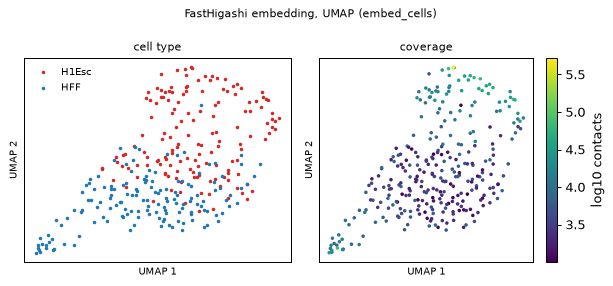

In [8]:
emb.embed_cells(cd, source="higashi", matrix=cd.cellm["higashi"], normalization="none", n_pcs=20,
                features="FastHigashi (rank 64, conv + rwr + col), coverage-corrected, L2-normalised")
leiden = emb.cluster_cells(cd, use="higashi_pca", resolution=0.5, key_added="leiden_higashi")
print(f"{leiden.nunique()} Leiden clusters: ARI {adjusted_rand_score(y, leiden):.3f}, "
      f"NMI {normalized_mutual_info_score(y, leiden):.3f}")
display(pd.crosstab(leiden, [cd.cells["cell_type"], cd.cells["fasthigashi_qc"]]).rename_axis(index="leiden_higashi"))

xy = cd.cellm["higashi_umap"]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for t, color in [("H1Esc", "tab:red"), ("HFF", "tab:blue")]:
    m = y == t
    axes[0].scatter(xy[m, 0], xy[m, 1], s=8, lw=0, color=color, label=t)
axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("cell type", fontsize=9)
sc = axes[1].scatter(xy[:, 0], xy[:, 1], s=8, lw=0, c=np.log10(cd.cells["n_contacts"]), cmap="viridis")
fig.colorbar(sc, ax=axes[1], label="log10 contacts"); axes[1].set_title("coverage", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP 1", fontsize=8); ax.set_ylabel("UMAP 2", fontsize=8)
fig.suptitle("FastHigashi embedding, UMAP (embed_cells)", fontsize=9)
fig.tight_layout()

Leiden gives the same picture as k-means.  Most cells that pass QC fall into two clusters, one for each cell
type, while most low-coverage cells form a third, mixed cluster.  The UMAP shows this too: the cells with many
contacts separate by type, and those with few contacts mix.

## 7. Store the result

The embedding and its provenance stay with the cells: `cd.cellm["higashi"]` holds the embedding, and
`cd.uns["higashi"]` holds the method, rank, variant and FastHigashi's config and result directory.  FastHigashi's
imputed per-cell maps can be large, so they stay in that result directory; `ChromData` keeps no per-cell
pairwise matrices.

In [9]:
path = OUT / "kim2020_higashi.chromdata.zarr"
cd.write(path)
back = ChromData.read(path)
print(path.relative_to(REPO), "| cellm:", sorted(back.cellm),
      "| equal:", np.allclose(back.cellm["higashi"], cd.cellm["higashi"]))
print("result directory:", Path(back.uns["higashi"]["result_dir"]).relative_to(REPO))
print(f"total runtime {time.time() - T0:.0f} s")

tutorials/_out/kim2020_higashi.chromdata.zarr | cellm: ['higashi', 'higashi_pca', 'higashi_tsne', 'higashi_umap'] | equal: True
result directory: tutorials/_out/higashi_kim2020/result
total runtime 136 s


## Next steps

- `cell_embeddings.ipynb`: RNA, ATAC, contact-map (scHiCluster) and IF embeddings of the same cells, Leiden
  clusters, marker features, and how the web browser reads `cd.uns["embeddings"]`.
- `chromdata_basics.ipynb`: the `ChromData` container.
- To embed all 1,931 cells, use `sub = labels.copy()` instead of the random sample.  This takes longer on a CPU;
  FastHigashi uses a CUDA GPU when one is available.